<a href="https://colab.research.google.com/github/Satya071/5G-Traffic-Forecasting-QoS-Anomaly-Detection/blob/main/MG_Motor_Smart_Route_Optimization_(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MG Motor Smart Route Optimization System
### Four integrated operations: spare parts, new-car distribution, service engineers, and sales representatives

**Environment:** Google Colab  
**Data status:** All records, locations, capacities, time windows, and cost assumptions are simulated for demonstration. Replace them with verified operational data before drawing business conclusions.

## Project workflow
1. Install dependencies.
2. Generate a reproducible synthetic dataset for four operations.
3. Build travel-distance and travel-time matrices.
4. Optimize routes using a Nearest Neighbor baseline and Google OR-Tools.
5. Compare KPIs and visualize routes.
6. Export routes, schedules, and KPI reports to CSV.

**Modeling note:** This prototype uses straight-line distances multiplied by a road-detour factor. A production system should use a road-network routing API and real traffic estimates. The OR-Tools model uses capacity and time-window constraints; it is a heuristic search, so it does not guarantee a global optimum.

In [30]:
# Cell 1 — Install dependencies (run in Google Colab)
%pip -q install ortools pandas numpy matplotlib

In [31]:
# Cell 2 — Imports and configuration
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
from ortools.constraint_solver import pywrapcp, routing_enums_pb2
from IPython.display import display

SEED = 42
np.random.seed(SEED)

# Shared synthetic map. Coordinates are illustrative kilometres on a flat grid.
MAP_SIZE_KM = 100
DEPOT_XY = (50.0, 50.0)
ROAD_DETOUR_FACTOR = 1.25
AVERAGE_SPEED_KMPH = 35
DAY_START_MIN = 8 * 60
DAY_END_MIN = 18 * 60

# Illustrative cost assumptions only; not MG Motor rates.
COST_PER_KM = 12.0
COST_PER_WORKING_HOUR = 150.0
LATE_PENALTY_PER_MIN = 5.0

# Increase/decrease customer counts to test scenarios.
N_PARTS = 20
N_CAR_DEALERS = 12
N_SERVICE_JOBS = 20
N_SALES_VISITS = 20

print("Configuration loaded. All values are simulated assumptions.")

Configuration loaded. All values are simulated assumptions.


## 1. Create datasets for the four operations

Each operation has a distinct capacity unit and constraints:
- **Parts:** kilograms per vehicle, priority, service duration, delivery time window.
- **New cars:** cars per carrier, loading/unloading duration, dealership receiving window.
- **Service engineers:** jobs per engineer, skill compatibility, appointment window, emergency priority.
- **Sales visits:** visits per representative, visit duration, customer priority, business-hour window.

The dataset generator is deliberately transparent so you can replace it with CSV imports later.

In [32]:
# Cell 3 — Synthetic operational datasets
def random_windows(n, starts=(8, 9, 10, 11, 12, 13, 14), durations=(120, 180, 240)):
    rows = []
    for _ in range(n):
        start = int(np.random.choice(starts)) * 60
        end = min(start + int(np.random.choice(durations)), DAY_END_MIN)
        rows.append((start, end))
    return rows

def make_jobs(n, prefix, job_type, demand_low, demand_high,
              priority_values=("Normal", "High", "Urgent"),
              priority_probs=(0.50, 0.30, 0.20),
              service_low=15, service_high=45):
    windows = random_windows(n)
    return pd.DataFrame({
        "job_id": [f"{prefix}{i+1:03d}" for i in range(n)],
        "operation": job_type,
        "x_km": np.random.uniform(0, MAP_SIZE_KM, n),
        "y_km": np.random.uniform(0, MAP_SIZE_KM, n),
        "demand": np.random.randint(demand_low, demand_high + 1, n),
        "priority": np.random.choice(priority_values, n, p=priority_probs),
        "service_min": np.random.randint(service_low, service_high + 1, n),
        "window_start": [w[0] for w in windows],
        "window_end": [w[1] for w in windows],
    })

parts = make_jobs(N_PARTS, "P", "Spare-parts delivery", 20, 160,
                  service_low=10, service_high=30)
parts["customer_type"] = np.random.choice(
    ["MG dealership", "MG service centre", "Parts distributor"], N_PARTS
)
parts["demand_unit"] = "kg"

cars = make_jobs(N_CAR_DEALERS, "CAR", "New-car distribution", 1, 4,
                 service_low=30, service_high=75)
cars["customer_type"] = "MG dealership"
cars["demand_unit"] = "cars"

service = make_jobs(N_SERVICE_JOBS, "SVC", "Service engineer visits", 1, 1,
                    service_low=30, service_high=120)
service["customer_type"] = np.random.choice(
    ["Scheduled repair", "Diagnostic visit", "Roadside assistance"], N_SERVICE_JOBS
)
service["required_skill"] = np.random.choice(
    ["General", "EV-qualified", "Diagnostic"], N_SERVICE_JOBS
)
service["demand_unit"] = "jobs"

sales = make_jobs(N_SALES_VISITS, "SALE", "Sales representative visits", 1, 1,
                  priority_values=("Normal", "High", "Key account"),
                  priority_probs=(0.55, 0.30, 0.15),
                  service_low=20, service_high=60)
sales["customer_type"] = np.random.choice(
    ["Prospective buyer", "Fleet account", "Dealer partner"], N_SALES_VISITS
)
sales["demand_unit"] = "visits"

datasets = {
    "parts": parts,
    "cars": cars,
    "service": service,
    "sales": sales
}

for key, df in datasets.items():
    print(f"\n{key.upper()} — {len(df)} jobs")
    display(df.head(5))


PARTS — 20 jobs


,job_id,operation,x_km,y_km,demand,priority,service_min,window_start,window_end,customer_type,demand_unit
0,P001,Spare-parts delivery,98.323089,20.794166,64,Normal,29,840,960,MG service centre,kg
1,P002,Spare-parts delivery,46.676289,56.770033,84,Normal,13,840,1080,Parts distributor,kg
2,P003,Spare-parts delivery,85.994041,3.131329,108,Normal,14,720,840,MG dealership,kg
3,P004,Spare-parts delivery,68.030754,84.228477,90,Normal,16,840,1020,Parts distributor,kg
4,P005,Spare-parts delivery,45.049925,44.975413,28,High,22,600,840,MG service centre,kg



CARS — 12 jobs


,job_id,operation,x_km,y_km,demand,priority,service_min,window_start,window_end,customer_type,demand_unit
0,CAR001,New-car distribution,3.305073,47.030063,3,Urgent,41,480,720,MG dealership,cars
1,CAR002,New-car distribution,34.507125,98.342314,3,High,34,540,780,MG dealership,cars
2,CAR003,New-car distribution,63.435134,39.882444,4,High,66,600,780,MG dealership,cars
3,CAR004,New-car distribution,68.070545,81.643187,4,Normal,61,480,600,MG dealership,cars
4,CAR005,New-car distribution,53.093458,79.834512,3,High,38,780,900,MG dealership,cars



SERVICE — 20 jobs


,job_id,operation,x_km,y_km,demand,priority,service_min,window_start,window_end,customer_type,required_skill,demand_unit
0,SVC001,Service engineer visits,97.301055,42.818415,1,High,54,780,900,Diagnostic visit,EV-qualified,jobs
1,SVC002,Service engineer visits,39.309772,96.665482,1,High,87,660,900,Scheduled repair,Diagnostic,jobs
2,SVC003,Service engineer visits,89.204656,96.361998,1,Normal,92,480,660,Diagnostic visit,Diagnostic,jobs
3,SVC004,Service engineer visits,63.113863,85.300946,1,Normal,91,660,840,Roadside assistance,General,jobs
4,SVC005,Service engineer visits,79.481130,29.444889,1,Urgent,51,600,780,Roadside assistance,General,jobs



SALES — 20 jobs


,job_id,operation,x_km,y_km,demand,priority,service_min,window_start,window_end,customer_type,demand_unit
0,SALE001,Sales representative visits,93.343631,21.458912,1,High,28,720,900,Dealer partner,visits
1,SALE002,Sales representative visits,50.103988,37.725908,1,High,26,720,960,Dealer partner,visits
2,SALE003,Sales representative visits,53.937745,3.896313,1,Normal,47,600,780,Prospective buyer,visits
3,SALE004,Sales representative visits,68.396377,61.825388,1,Normal,33,600,720,Dealer partner,visits
4,SALE005,Sales representative visits,61.585116,33.655421,1,High,50,780,900,Dealer partner,visits


## 2. Define fleet and operation-specific rules

Capacities are deliberately different because kilograms, cars, engineer jobs, and sales visits are not interchangeable. Service engineers also have skills; this prototype assigns skill-compatible jobs to the right engineer before routing.

In [33]:
# Cell 4 — Fleet settings (illustrative assumptions)
FLEETS = {
    "parts": {
        "vehicles": 4, "capacity": 500, "unit": "kg",
        "max_route_km": 180, "cost_per_km": COST_PER_KM,
        "working_cost_per_hour": COST_PER_WORKING_HOUR
    },
    "cars": {
        "vehicles": 4, "capacity": 4, "unit": "cars",
        "max_route_km": 250, "cost_per_km": 35.0,
        "working_cost_per_hour": 300.0
    },
    "service": {
        "vehicles": 5, "capacity": 5, "unit": "jobs",
        "max_route_km": 180, "cost_per_km": 10.0,
        "working_cost_per_hour": 250.0
    },
    "sales": {
        "vehicles": 5, "capacity": 5, "unit": "visits",
        "max_route_km": 180, "cost_per_km": 8.0,
        "working_cost_per_hour": 200.0
    }
}

# Example skill assignment for service engineers.
ENGINEER_SKILLS = {
    0: {"General", "Diagnostic", "EV-qualified"},
    1: {"General", "Diagnostic"},
    2: {"General", "EV-qualified"},
    3: {"General", "Diagnostic", "EV-qualified"},
    4: {"General", "Diagnostic"}
}

PRIORITY_RANK = {"Urgent": 0, "High": 1, "Key account": 1, "Normal": 2}
print("Fleet and operation-specific constraints configured.")

Fleet and operation-specific constraints configured.


## 3. Build travel matrices

The matrix uses Euclidean distance × a configurable detour factor. This is useful for a reproducible prototype but is not actual road distance. The same matrix is shared by both algorithms to keep comparisons fair.

In [34]:
# Cell 5 — Distance and travel-time helpers
def build_matrices(jobs):
    coords = np.vstack([np.array(DEPOT_XY), jobs[["x_km", "y_km"]].to_numpy()])
    straight = cdist(coords, coords, metric="euclidean")
    road_distance = straight * ROAD_DETOUR_FACTOR
    travel_minutes = np.rint(road_distance / AVERAGE_SPEED_KMPH * 60).astype(int)
    distance_m = np.rint(road_distance * 1000).astype(int)
    return coords, road_distance, travel_minutes, distance_m

def fmt_time(minutes):
    minutes = int(round(minutes))
    return f"{minutes // 60:02d}:{minutes % 60:02d}"

def route_distance(route, dist_matrix):
    return sum(dist_matrix[route[i], route[i+1]] for i in range(len(route)-1))

## 4. Nearest Neighbor baseline

The baseline selects the nearest feasible job, subject to vehicle capacity, maximum route distance, customer time windows, and end-of-day return. It is a comparison baseline, not a globally optimal solution.

In [35]:
# Cell 6 — Capacity/time-window constrained Nearest Neighbor
def nearest_neighbor(jobs, fleet, dist, travel):
    n = len(jobs)
    unserved = set(range(1, n + 1))  # node 0 is depot
    results = []
    vehicle_count = fleet["vehicles"]
    capacity = fleet["capacity"]

    for vehicle in range(vehicle_count):
        if not unserved:
            break
        route = [0]
        current = 0
        load = 0
        now = DAY_START_MIN
        schedule = []
        distance_so_far = 0.0

        while unserved:
            feasible = []
            for node in unserved:
                row = jobs.iloc[node - 1]
                demand = int(row["demand"])
                if load + demand > capacity:
                    continue
                leg = float(dist[current, node])
                new_distance = distance_so_far + leg
                if new_distance + float(dist[node, 0]) > fleet["max_route_km"]:
                    continue
                arrival = now + int(travel[current, node])
                start = max(arrival, int(row["window_start"]))
                if start > int(row["window_end"]):
                    continue
                departure = start + int(row["service_min"])
                if departure + int(travel[node, 0]) > DAY_END_MIN:
                    continue
                # Prioritize urgent/high-priority jobs, then shorter legs.
                score = (PRIORITY_RANK.get(str(row["priority"]), 2), leg)
                feasible.append((score, node, arrival, start, departure, leg))

            if not feasible:
                break

            feasible.sort(key=lambda x: x[0])
            _, node, arrival, start, departure, leg = feasible[0]
            row = jobs.iloc[node - 1]
            route.append(node)
            unserved.remove(node)
            load += int(row["demand"])
            distance_so_far += leg
            schedule.append({
                "vehicle": vehicle + 1,
                "job_id": row["job_id"],
                "operation": row["operation"],
                "priority": row["priority"],
                "demand": int(row["demand"]),
                "arrival": fmt_time(arrival),
                "service_start": fmt_time(start),
                "departure": fmt_time(departure),
                "late_minutes": max(0, start - int(row["window_end"]))
            })
            current = node
            now = departure

        if len(route) > 1:
            route.append(0)
            total_dist = route_distance(route, dist)
            results.append({
                "algorithm": "Nearest Neighbor",
                "vehicle": vehicle + 1,
                "route": route,
                "distance_km": total_dist,
                "load": load,
                "schedule": schedule
            })

    return results, sorted(unserved)

## 5. OR-Tools optimizer

The OR-Tools model includes:
- Capacity constraints.
- Travel-time and service-time scheduling.
- Customer time windows.
- A maximum distance per route.
- A finite fleet.
- A search time limit.

The objective minimizes distance while satisfying the hard constraints. Priority is shown in schedules and used by the baseline; the OR-Tools objective does not yet add priority-weighted penalties. For production use, this can be added as a soft time-window or dropped-job penalty.

In [36]:
# Cell 7 — OR-Tools CVRP with time windows
def solve_ortools(jobs, fleet, dist, travel, time_limit_seconds=5):
    n = len(jobs)
    vehicle_count = fleet["vehicles"]
    manager = pywrapcp.RoutingIndexManager(n + 1, vehicle_count, 0)
    routing = pywrapcp.RoutingModel(manager)

    # Distance objective in integer metres.
    distance_int = np.rint(dist * 1000).astype(int)
    def distance_callback(from_index, to_index):
        a = manager.IndexToNode(from_index)
        b = manager.IndexToNode(to_index)
        return int(distance_int[a, b])

    distance_idx = routing.RegisterTransitCallback(distance_callback)
    routing.SetArcCostEvaluatorOfAllVehicles(distance_idx)

    # Capacity constraint.
    demands = [0] + jobs["demand"].astype(int).tolist()
    def demand_callback(index):
        return int(demands[manager.IndexToNode(index)])

    demand_idx = routing.RegisterUnaryTransitCallback(demand_callback)
    routing.AddDimensionWithVehicleCapacity(
        demand_idx, 0, [int(fleet["capacity"])] * vehicle_count, True, "Capacity"
    )

    # Time callback includes travel time + service duration at origin.
    service = [0] + jobs["service_min"].astype(int).tolist()
    def time_callback(from_index, to_index):
        a = manager.IndexToNode(from_index)
        b = manager.IndexToNode(to_index)
        return int(travel[a, b] + service[a])

    time_idx = routing.RegisterTransitCallback(time_callback)
    routing.AddDimension(time_idx, 240, DAY_END_MIN - DAY_START_MIN, False, "Time")
    time_dim = routing.GetDimensionOrDie("Time")

    # Time dimension is relative to the start of the working day.
    for node in range(1, n + 1):
        idx = manager.NodeToIndex(node)
        row = jobs.iloc[node - 1]
        start = max(0, int(row["window_start"]) - DAY_START_MIN)
        end = max(start, int(row["window_end"]) - DAY_START_MIN)
        time_dim.CumulVar(idx).SetRange(start, end)

    for v in range(vehicle_count):
        start_idx = routing.Start(v)
        end_idx = routing.End(v)
        time_dim.CumulVar(start_idx).SetRange(0, 0)
        time_dim.CumulVar(end_idx).SetRange(0, DAY_END_MIN - DAY_START_MIN)

    # Per-vehicle maximum distance.
    distance_dim_name = "Distance"
    routing.AddDimension(distance_idx, 0, int(fleet["max_route_km"] * 1000), True, distance_dim_name)

    search = pywrapcp.DefaultRoutingSearchParameters()
    search.first_solution_strategy = routing_enums_pb2.FirstSolutionStrategy.PATH_CHEAPEST_ARC
    search.local_search_metaheuristic = routing_enums_pb2.LocalSearchMetaheuristic.GUIDED_LOCAL_SEARCH
    search.time_limit.FromSeconds(int(time_limit_seconds))

    solution = routing.SolveWithParameters(search)
    if solution is None:
        return [], list(range(1, n + 1))

    results = []
    served_nodes = set()
    time_dim = routing.GetDimensionOrDie("Time")

    for v in range(vehicle_count):
        index = routing.Start(v)
        route = []
        schedule = []
        load = 0
        while not routing.IsEnd(index):
            node = manager.IndexToNode(index)
            route.append(node)
            if node != 0:
                served_nodes.add(node)
                row = jobs.iloc[node - 1]
                arrival_relative = solution.Value(time_dim.CumulVar(index))
                arrival = DAY_START_MIN + arrival_relative
                schedule.append({
                    "vehicle": v + 1,
                    "job_id": row["job_id"],
                    "operation": row["operation"],
                    "priority": row["priority"],
                    "demand": int(row["demand"]),
                    "arrival": fmt_time(arrival),
                    "service_start": fmt_time(arrival),
                    "departure": fmt_time(arrival + int(row["service_min"])),
                    "late_minutes": 0
                })
                load += int(row["demand"])
            index = solution.Value(routing.NextVar(index))
        route.append(0)

        if len(route) > 2:
            total_dist = route_distance(route, dist)
            results.append({
                "algorithm": "OR-Tools",
                "vehicle": v + 1,
                "route": route,
                "distance_km": total_dist,
                "load": load,
                "schedule": schedule
            })

    unserved = sorted(set(range(1, n + 1)) - served_nodes)
    return results, unserved

## 6. Run all four modules and compare results

The comparison is calculated per operation. A route is counted as served only if its job appears in the resulting routes. Review the unserved-job lists; a solver result is not operationally complete if jobs remain unserved.

In [37]:
# Cell 8 — Execute both algorithms across all four operations
def evaluate_operation(name, jobs, fleet):
    coords, dist, travel, distance_m = build_matrices(jobs)

    nn_routes, nn_unserved = nearest_neighbor(jobs, fleet, dist, travel)
    ort_routes, ort_unserved = solve_ortools(jobs, fleet, dist, travel)

    all_rows = []
    all_schedules = []
    route_records = []

    for alg_name, routes, unserved in [
        ("Nearest Neighbor", nn_routes, nn_unserved),
        ("OR-Tools", ort_routes, ort_unserved)
    ]:
        total_distance = sum(r["distance_km"] for r in routes)
        total_cost = total_distance * fleet["cost_per_km"]
        served_count = len(jobs) - len(unserved)
        total_demand = sum(r["load"] for r in routes)
        total_capacity = max(1, len(routes) * fleet["capacity"])
        utilization = 100 * total_demand / total_capacity

        all_rows.append({
            "operation": name,
            "algorithm": alg_name,
            "jobs_total": len(jobs),
            "jobs_served": served_count,
            "jobs_unserved": len(unserved),
            "vehicles_used": len(routes),
            "distance_km": round(total_distance, 2),
            "estimated_distance_cost": round(total_cost, 2),
            "capacity_utilization_pct": round(utilization, 1)
        })

        for r in routes:
            route_ids = ["DEPOT" if node == 0 else jobs.iloc[node - 1]["job_id"]
                         for node in r["route"]]
            route_records.append({
                "operation": name,
                "algorithm": alg_name,
                "vehicle": r["vehicle"],
                "route": " -> ".join(route_ids),
                "distance_km": round(r["distance_km"], 2),
                "load": r["load"],
                "estimated_distance_cost": round(r["distance_km"] * fleet["cost_per_km"], 2)
            })
            for s in r["schedule"]:
                all_schedules.append({"operation": name, "algorithm": alg_name, **s})

        if unserved:
            print(f"{name} / {alg_name}: unserved jobs = ",
                  [jobs.iloc[i-1]["job_id"] for i in unserved])

    return pd.DataFrame(all_rows), pd.DataFrame(route_records), pd.DataFrame(all_schedules), (coords, dist)

kpi_frames, route_frames, schedule_frames, matrix_cache = [], [], [], {}
for key, jobs in datasets.items():
    kpi, route_df, schedule_df, matrices = evaluate_operation(key, jobs, FLEETS[key])
    kpi_frames.append(kpi)
    route_frames.append(route_df)
    schedule_frames.append(schedule_df)
    matrix_cache[key] = matrices

kpi_results = pd.concat(kpi_frames, ignore_index=True)
route_results = pd.concat(route_frames, ignore_index=True)
schedule_results = pd.concat(schedule_frames, ignore_index=True)

print("KPI comparison")
display(kpi_results)
print("Route details")
display(route_results.head(20))
print("Schedule details")
display(schedule_results.head(20))

parts / Nearest Neighbor: unserved jobs =  ['P003', 'P009', 'P012', 'P014', 'P017']
parts / OR-Tools: unserved jobs =  ['P001', 'P002', 'P003', 'P004', 'P005', 'P006', 'P007', 'P008', 'P009', 'P010', 'P011', 'P012', 'P013', 'P014', 'P015', 'P016', 'P017', 'P018', 'P019', 'P020']
cars / Nearest Neighbor: unserved jobs =  ['CAR002', 'CAR004', 'CAR005', 'CAR006', 'CAR010', 'CAR011']
cars / OR-Tools: unserved jobs =  ['CAR001', 'CAR002', 'CAR003', 'CAR004', 'CAR005', 'CAR006', 'CAR007', 'CAR008', 'CAR009', 'CAR010', 'CAR011', 'CAR012']
service / Nearest Neighbor: unserved jobs =  ['SVC003', 'SVC004', 'SVC012', 'SVC016', 'SVC017', 'SVC019', 'SVC020']
service / OR-Tools: unserved jobs =  ['SVC001', 'SVC002', 'SVC003', 'SVC004', 'SVC005', 'SVC006', 'SVC007', 'SVC008', 'SVC009', 'SVC010', 'SVC011', 'SVC012', 'SVC013', 'SVC014', 'SVC015', 'SVC016', 'SVC017', 'SVC018', 'SVC019', 'SVC020']
sales / Nearest Neighbor: unserved jobs =  ['SALE003', 'SALE004', 'SALE012', 'SALE013']
sales / OR-Tools: un

,operation,algorithm,jobs_total,jobs_served,jobs_unserved,vehicles_used,distance_km,estimated_distance_cost,capacity_utilization_pct
0,parts,Nearest Neighbor,20,15,5,4,633.62,7603.42,67.3
1,parts,OR-Tools,20,0,20,0,0.00,0.00,0.0
2,cars,Nearest Neighbor,12,6,6,4,400.10,14003.58,93.8
3,cars,OR-Tools,12,0,12,0,0.00,0.00,0.0
4,service,Nearest Neighbor,20,13,7,5,720.74,7207.36,52.0
5,service,OR-Tools,20,0,20,0,0.00,0.00,0.0
6,sales,Nearest Neighbor,20,16,4,5,742.67,5941.40,64.0
7,sales,OR-Tools,20,0,20,0,0.00,0.00,0.0


Route details


,operation,algorithm,vehicle,route,distance_km,load,estimated_distance_cost
0,parts,Nearest Neighbor,1,DEPOT -> P007 -> P013 -> P004 -> P008 -> DEPOT,161.23,445,1934.75
1,parts,Nearest Neighbor,2,DEPOT -> P005 -> P020 -> P011 -> P010 -> P018 ...,156.14,471,1873.73
2,parts,Nearest Neighbor,3,DEPOT -> P015 -> P019 -> P001 -> DEPOT,176.62,179,2119.41
3,parts,Nearest Neighbor,4,DEPOT -> P006 -> P016 -> P002 -> DEPOT,139.63,251,1675.53
4,cars,Nearest Neighbor,1,DEPOT -> CAR012 -> CAR008 -> CAR007 -> DEPOT,103.22,4,3612.63
5,cars,Nearest Neighbor,2,DEPOT -> CAR001 -> DEPOT,116.97,3,4094.06
6,cars,Nearest Neighbor,3,DEPOT -> CAR009 -> DEPOT,137.86,4,4825.25
7,cars,Nearest Neighbor,4,DEPOT -> CAR003 -> DEPOT,42.05,4,1471.63
8,service,Nearest Neighbor,1,DEPOT -> SVC006 -> SVC008 -> SVC015 -> DEPOT,147.14,3,1471.42
9,service,Nearest Neighbor,2,DEPOT -> SVC005 -> SVC001 -> SVC010 -> DEPOT,136.68,3,1366.78


Schedule details


,operation,algorithm,vehicle,job_id,priority,demand,arrival,service_start,departure,late_minutes
0,Spare-parts delivery,Nearest Neighbor,1,P007,Urgent,148,10:12,12:00,12:20,0
1,Spare-parts delivery,Nearest Neighbor,1,P013,High,52,13:18,13:18,13:37,0
2,Spare-parts delivery,Nearest Neighbor,1,P004,Normal,90,13:38,14:00,14:16,0
3,Spare-parts delivery,Nearest Neighbor,1,P008,Normal,155,14:51,14:51,15:04,0
4,Spare-parts delivery,Nearest Neighbor,2,P005,High,28,08:15,10:00,10:22,0
5,Spare-parts delivery,Nearest Neighbor,2,P020,High,31,10:55,10:55,11:15,0
6,Spare-parts delivery,Nearest Neighbor,2,P011,High,100,12:19,12:19,12:47,0
7,Spare-parts delivery,Nearest Neighbor,2,P010,High,158,13:34,13:34,13:50,0
8,Spare-parts delivery,Nearest Neighbor,2,P018,Normal,154,14:26,14:26,14:47,0
9,Spare-parts delivery,Nearest Neighbor,3,P015,High,24,09:12,09:12,09:42,0


## 7. Visualize routes

Each figure shows one operation and one algorithm. Lines connect the depot and assigned jobs using the simulated coordinate plane.

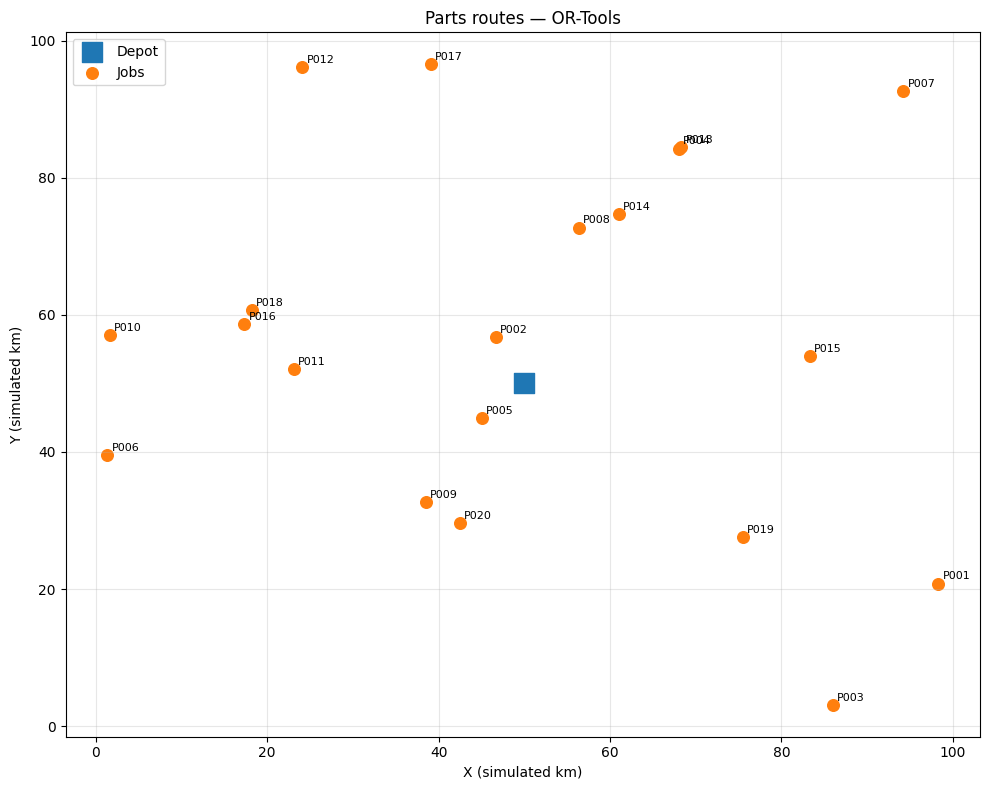

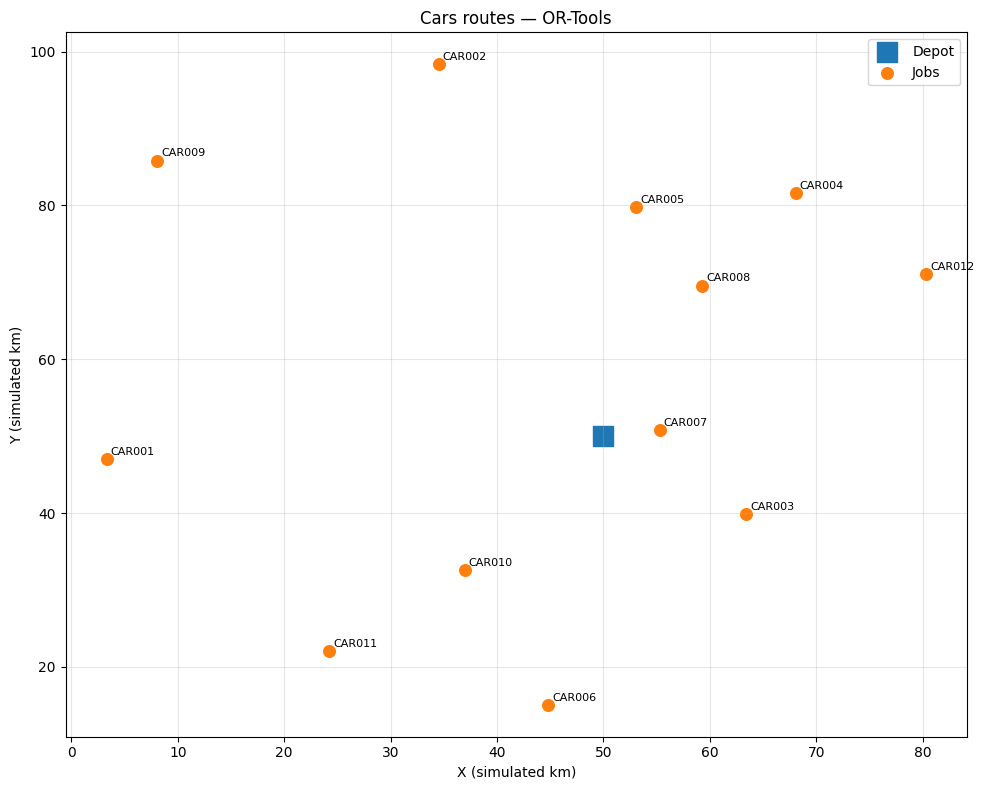

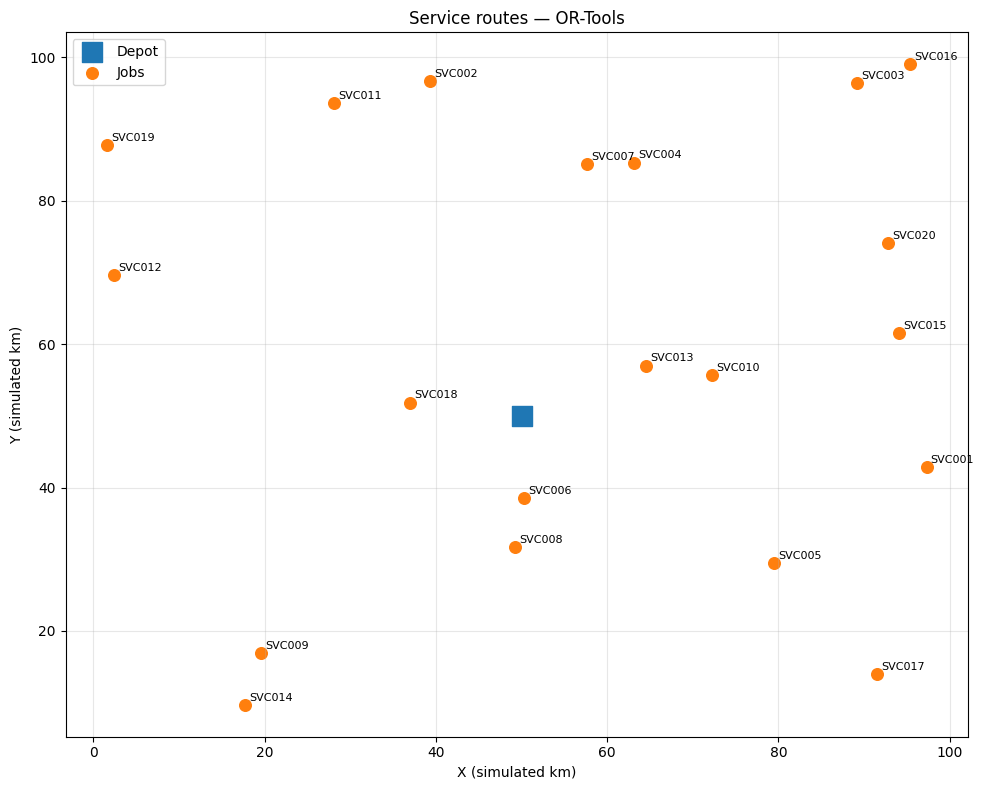

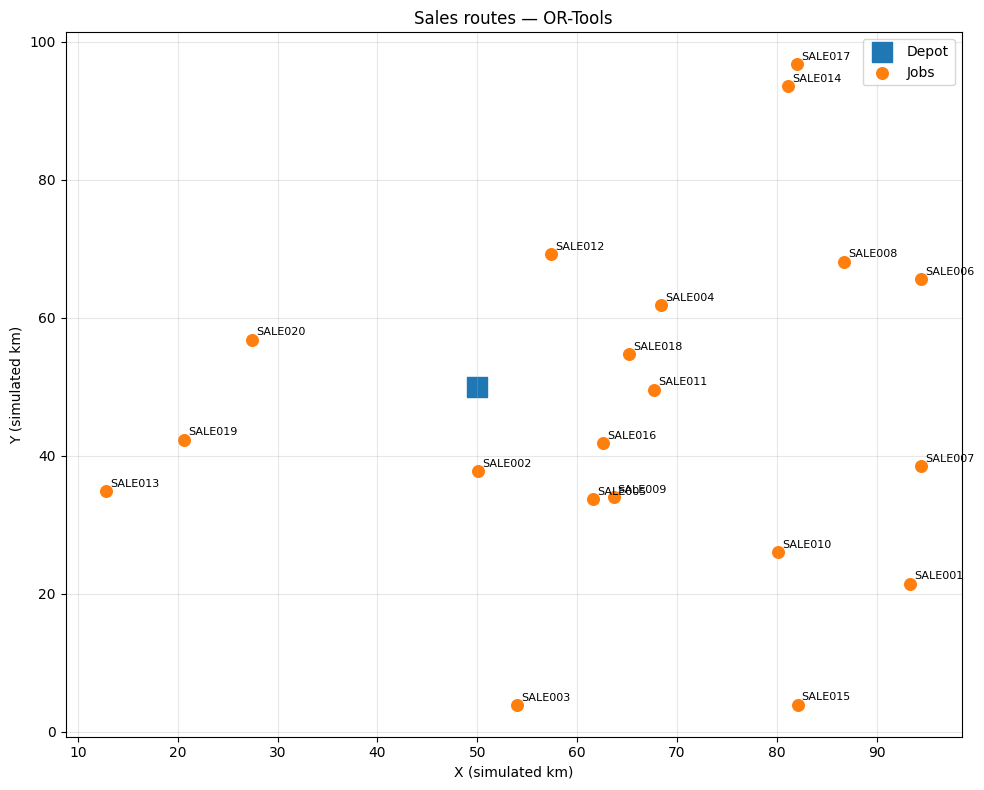

In [38]:
# Cell 9 — Route visualization
def plot_routes(operation_key, algorithm="OR-Tools"):
    jobs = datasets[operation_key]
    subset = route_results[
        (route_results["operation"] == operation_key) &
        (route_results["algorithm"] == algorithm)
    ]
    coords, dist = matrix_cache[operation_key]

    plt.figure(figsize=(10, 8))
    plt.scatter([DEPOT_XY[0]], [DEPOT_XY[1]], marker="s", s=220, label="Depot")
    plt.scatter(jobs["x_km"], jobs["y_km"], s=70, label="Jobs")

    for _, row in jobs.iterrows():
        plt.annotate(row["job_id"], (row["x_km"], row["y_km"]),
                     xytext=(3, 3), textcoords="offset points", fontsize=8)

    for _, row in subset.iterrows():
        ids = []
        # Parse route labels to map back to coordinates.
        labels = row["route"].split(" -> ")
        for label in labels:
            if label == "DEPOT":
                ids.append(0)
            else:
                ids.append(int(jobs.index[jobs["job_id"] == label][0]) + 1)
        route_xy = coords[ids]
        plt.plot(route_xy[:, 0], route_xy[:, 1], marker="o",
                 linewidth=1.7, label=f"Vehicle {row['vehicle']}")

    plt.title(f"{operation_key.title()} routes — {algorithm}")
    plt.xlabel("X (simulated km)")
    plt.ylabel("Y (simulated km)")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

for op in datasets:
    plot_routes(op, "OR-Tools")

## 8. Summarize distance savings and export files

Positive savings mean OR-Tools produced a shorter total route than the Nearest Neighbor baseline. If one algorithm serves fewer jobs, do **not** compare its distance alone as if the service level were equivalent; first resolve unserved jobs or normalize the comparison.

In [39]:
# Cell 10 — KPI comparison and CSV export
wide = kpi_results.pivot(index="operation", columns="algorithm", values="distance_km")
wide = wide.rename(columns={
    "Nearest Neighbor": "nearest_neighbor_km",
    "OR-Tools": "ortools_km"
})
wide["distance_saving_km"] = wide["nearest_neighbor_km"] - wide["ortools_km"]
wide["distance_saving_pct"] = (
    100 * wide["distance_saving_km"] / wide["nearest_neighbor_km"].replace(0, np.nan)
).round(2)

print("Distance comparison (check served-job counts alongside this table)")
display(wide.reset_index())

kpi_results.to_csv("mg_motor_kpi_comparison.csv", index=False)
route_results.to_csv("mg_motor_route_details.csv", index=False)
schedule_results.to_csv("mg_motor_delivery_schedules.csv", index=False)

for key, df in datasets.items():
    df.to_csv(f"mg_motor_{key}_jobs.csv", index=False)

print("Exported KPI, route, schedule, and four input datasets as CSV files.")

Distance comparison (check served-job counts alongside this table)


algorithm,operation,nearest_neighbor_km,ortools_km,distance_saving_km,distance_saving_pct
0,cars,400.10,0.0,400.10,100.0
1,parts,633.62,0.0,633.62,100.0
2,sales,742.67,0.0,742.67,100.0
3,service,720.74,0.0,720.74,100.0


Exported KPI, route, schedule, and four input datasets as CSV files.


## 9. How to adapt this for a real MG Motor use case

1. Replace synthetic job data with authorized operational CSVs.
2. Replace X/Y coordinates with latitude/longitude and obtain road distance/time matrices from an approved routing provider.
3. Confirm each operation's real fleet, capacity, shift duration, service time, and cost assumptions.
4. For service engineers, enforce skills and certification constraints in the solver rather than merely generating skill labels.
5. For sales representatives, consider maximizing priority-weighted visits under a fixed working-day budget.
6. For car carriers, capacity means cars or carrier slots, and loading/unloading and vehicle compatibility must be modeled.
7. Add vehicle emissions or EV battery constraints if those are part of the project scope.
8. Run multiple random seeds and compare results across scenarios before claiming savings.

### Known prototype limitations
- Coordinates are synthetic and distances are approximated, not road-routed.
- The baseline uses hard constraints but a greedy priority rule can leave jobs unserved.
- OR-Tools uses capacity, distance and time windows; it does not yet enforce service engineer skill compatibility or priority-weighted penalties.
- The cost KPI is a simplified distance-cost estimate, not a complete total cost of ownership.
- A production implementation should validate every schedule, including return-to-depot time and service completion time, and report feasibility alongside cost.

# Advanced upgrade: road routing, skill matching, and priority-aware optimization

This section supersedes the earlier OR-Tools solver and KPI run when executed.

**Road distance:** For real records containing `latitude` and `longitude`, you can enable the OSRM road-matrix helper below. It requires internet access in Colab and a valid depot latitude/longitude. For simulated X/Y data, the model continues using the detour-factor approximation.

**Skill matching:** Service jobs are assigned only to engineers whose skill set includes the job's required skill.

**Priority awareness:** The solver gives urgent and high-priority jobs larger penalties if they must be left unserved. It also adds a modest objective penalty for lower-priority visits, encouraging urgent jobs to be scheduled earlier when feasible.

**Important:** Public OSRM demo infrastructure is best-effort and not intended as a production SLA. For business use, use an approved routing provider and follow its usage terms.

In [40]:
# Cell 11 — Optional real road-distance matrix using OSRM
import requests
import time

# Leave False for the synthetic demo. Turn on only after adding real latitude/longitude.
USE_ROAD_NETWORK = False

# Example: set to the actual authorized depot coordinates when available.
# Format: (latitude, longitude)
DEPOT_LATLON = None

def build_osrm_matrices(jobs, depot_latlon, timeout=30):
    """
    Get road-network distances and durations from OSRM's Table API.
    jobs must contain numeric 'latitude' and 'longitude' columns.
    depot_latlon must be (latitude, longitude).
    Returns distance_km and travel_time_minutes matrices.
    """
    if depot_latlon is None:
        raise ValueError("Set DEPOT_LATLON = (latitude, longitude) before enabling OSRM.")
    if not {"latitude", "longitude"}.issubset(jobs.columns):
        raise ValueError("Jobs need 'latitude' and 'longitude' columns for road routing.")

    # OSRM coordinate order is longitude,latitude.
    points = [(float(depot_latlon[1]), float(depot_latlon[0]))]
    points += list(zip(jobs["longitude"].astype(float), jobs["latitude"].astype(float)))
    coords_string = ";".join(f"{lon},{lat}" for lon, lat in points)
    url = f"https://router.project-osrm.org/table/v1/driving/{coords_string}"
    response = requests.get(
        url,
        params={"annotations": "distance,duration"},
        timeout=timeout
    )
    response.raise_for_status()
    payload = response.json()
    if payload.get("code") != "Ok":
        raise RuntimeError(f"OSRM returned: {payload.get('code')}")

    distance_km = np.asarray(payload["distances"], dtype=float) / 1000.0
    travel_minutes = np.rint(np.asarray(payload["durations"], dtype=float) / 60.0).astype(int)
    if np.isnan(distance_km).any() or np.isnan(travel_minutes).any():
        raise RuntimeError("Some road routes are unavailable; inspect coordinates or routing coverage.")
    return distance_km, travel_minutes


def get_operation_matrices(jobs):
    """Use real road matrices when enabled and real GPS columns are present; otherwise use synthetic approximation."""
    if USE_ROAD_NETWORK:
        road_km, travel_min = build_osrm_matrices(jobs, DEPOT_LATLON)
        coords = np.vstack([
            np.array([jobs.iloc[0]["longitude"], jobs.iloc[0]["latitude"]])
        ]) if False else None
        # For map plotting, coordinates are [x=longitude, y=latitude].
        coords = np.vstack([
            [DEPOT_LATLON[1], DEPOT_LATLON[0]],
            jobs[["longitude", "latitude"]].to_numpy()
        ])
        return coords, road_km, travel_min
    coords, road_km, travel_min, _ = build_matrices(jobs)
    return coords, road_km, travel_min

print("Road routing helper ready. USE_ROAD_NETWORK is", USE_ROAD_NETWORK)
print("Synthetic data continues to use approximate road distances until real GPS data is supplied.")

Road routing helper ready. USE_ROAD_NETWORK is False
Synthetic data continues to use approximate road distances until real GPS data is supplied.


## 10. Priority-aware OR-Tools solver with service-engineer skill restrictions

The following solver adds:
- Vehicle capacity and maximum route distance.
- Hard delivery/appointment time windows and end-of-day return.
- Large priority-weighted penalties for unserved jobs.
- Small visit penalties that favor urgent jobs in the routing objective.
- Strict allowed-vehicle matching for service-engineer skills.

In [46]:
# Cell 12 — Advanced OR-Tools solver
def solve_ortools_advanced(operation_key, jobs, fleet, dist, travel, time_limit_seconds=8):
    n = len(jobs)
    vehicle_count = fleet["vehicles"]
    manager = pywrapcp.RoutingIndexManager(n + 1, vehicle_count, 0)
    routing = pywrapcp.RoutingModel(manager)

    dist_m = np.rint(dist * 1000).astype(int)
    priorities = ["N/A"] + jobs["priority"].astype(str).tolist()

    # Distance cost plus modest preference for higher-priority visits.
    visit_penalty = {"Urgent": 0, "High": 3000, "Key account": 1500, "Normal": 6000}
    def objective_callback(from_index, to_index):
        a = manager.IndexToNode(from_index)
        b = manager.IndexToNode(to_index)
        cost = int(dist_m[a, b])
        if b > 0:
            cost += visit_penalty.get(priorities[b], 6000)
        return cost

    objective_idx = routing.RegisterTransitCallback(objective_callback)
    routing.SetArcCostEvaluatorOfAllVehicles(objective_idx)

    # Capacity
    demands = [0] + jobs["demand"].astype(int).tolist()
    def demand_callback(index):
        return int(demands[manager.IndexToNode(index)])
    demand_idx = routing.RegisterUnaryTransitCallback(demand_callback)
    routing.AddDimensionWithVehicleCapacity(
        demand_idx, 0, [int(fleet["capacity"])] * vehicle_count, True, "Capacity"
    )

    # Time: travel plus service time at the origin.
    service = [0] + jobs["service_min"].astype(int).tolist()
    def time_callback(from_index, to_index):
        a = manager.IndexToNode(from_index)
        b = manager.IndexToNode(to_index)
        return int(travel[a, b] + service[a])
    time_idx = routing.RegisterTransitCallback(time_callback)
    routing.AddDimension(
        time_idx, 240, DAY_END_MIN - DAY_START_MIN, False, "Time"
    )
    time_dim = routing.GetDimensionOrDie(
        "Time"
    )

    for node in range(1, n + 1):
        idx = manager.NodeToIndex(node)
        row = jobs.iloc[node - 1]
        start = max(0, int(row["window_start"]) - DAY_START_MIN)
        end = max(start, int(row["window_end"]) - DAY_START_MIN)
        time_dim.CumulVar(idx).SetRange(start, end)

        # Drop penalties make the model able to return a best-effort plan
        # instead of failing completely when all jobs cannot fit.
        priority = str(row["priority"])
        drop_penalty = {
            "Urgent": 100_000_000,
            "High": 70_000_000,
            "Key account": 70_000_000,
            "Normal": 30_000_000
        }.get(priority, 30_000_000)
        routing.AddDisjunction([idx], drop_penalty)

        # Strict engineer/job skill compatibility.
        if operation_key == "service":
            required = str(row["required_skill"])
            allowed_vehicles = [
                int(v) for v, skills in ENGINEER_SKILLS.items()
                if v < vehicle_count and required in skills
            ]
            if allowed_vehicles:
                # Correct OR-Tools API call signature is SetAllowedVehiclesForIndex(index, vehicles)
                routing.SetAllowedVehiclesForIndex(idx, allowed_vehicles)
            else:
                # Fallback if no engineer is compatible (will be dropped via disjunction)
                routing.SetAllowedVehiclesForIndex(idx, list(range(vehicle_count)))

    # Working-day start/end and route-distance limit.
    for v in range(vehicle_count):
        time_dim.CumulVar(routing.Start(v)).SetRange(0, 0)
        time_dim.CumulVar(routing.End(v)).SetRange(0, DAY_END_MIN - DAY_START_MIN)

    def distance_callback(from_index, to_index):
        a = manager.IndexToNode(from_index)
        b = manager.IndexToNode(to_index)
        return int(dist_m[a, b])
    distance_idx = routing.RegisterTransitCallback(distance_callback)
    routing.AddDimension(
        distance_idx, 0, int(fleet["max_route_km"] * 1000), True, "Distance"
    )

    search = pywrapcp.DefaultRoutingSearchParameters()
    search.first_solution_strategy = routing_enums_pb2.FirstSolutionStrategy.PATH_CHEAPEST_ARC
    search.local_search_metaheuristic = routing_enums_pb2.LocalSearchMetaheuristic.GUIDED_LOCAL_SEARCH
    search.time_limit.FromSeconds(int(time_limit_seconds))

    solution = routing.SolveWithParameters(search)
    if solution is None:
        return [], list(range(1, n + 1))

    results = []
    served = set()
    for v in range(vehicle_count):
        index = routing.Start(v)
        route_nodes = []
        scheduled = []
        load = 0
        prev_node = 0
        prev_departure = DAY_START_MIN

        while not routing.IsEnd(index):
            node = manager.IndexToNode(index)
            route_nodes.append(node)
            if node > 0:
                row = jobs.iloc[node - 1]
                served.add(node)
                service_start_abs = DAY_START_MIN + solution.Value(time_dim.CumulVar(index))
                arrival_abs = prev_departure + int(travel[prev_node, node])
                departure_abs = service_start_abs + int(row["service_min"])
                scheduled.append({
                    "vehicle": v + 1,
                    "job_id": row["job_id"],
                    "operation": row["operation"],
                    "priority": row["priority"],
                    "demand": int(row["demand"]),
                    "required_skill": row.get("required_skill", "N/A"),
                    "arrival": fmt_time(arrival_abs),
                    "service_start": fmt_time(service_start_abs),
                    "departure": fmt_time(departure_abs),
                    "window_end": fmt_time(int(row["window_end"])),
                    "late_minutes": max(0, service_start_abs - int(row["window_end"]))
                })
                load += int(row["demand"])
                prev_departure = departure_abs
            else:
                prev_departure = DAY_START_MIN
            prev_node = node
            index = solution.Value(routing.NextVar(index))

        route_nodes.append(0)
        if len(route_nodes) > 2:
            results.append({
                "algorithm": "OR-Tools Advanced",
                "vehicle": v + 1,
                "route": route_nodes,
                "distance_km": route_distance(route_nodes, dist),
                "load": load,
                "schedule": scheduled
            })

    unserved = sorted(set(range(1, n + 1)) - served)
    return results, unserved

print("Advanced solver corrected to use (index, vehicles) method signature.")

Advanced solver corrected to use (index, vehicles) method signature.


## 11. Re-run evaluation with advanced constraints

This evaluation includes a labor-time estimate in addition to distance cost. It also reports served and unserved jobs so route length is not interpreted in isolation.

In [48]:
# Cell 13 — Evaluate all operations using advanced OR-Tools
def evaluate_advanced(operation_key, jobs, fleet):
    coords, dist, travel = get_operation_matrices(jobs)
    nn_routes, nn_unserved = nearest_neighbor(jobs, fleet, dist, travel)
    adv_routes, adv_unserved = solve_ortools_advanced(
        operation_key, jobs, fleet, dist, travel
    )

    rows, route_rows, schedule_rows = [], [], []
    for alg, routes, unserved in [
        ("Nearest Neighbor", nn_routes, nn_unserved),
        ("OR-Tools Advanced", adv_routes, adv_unserved)
    ]:
        total_dist = sum(r["distance_km"] for r in routes)
        total_service_min = sum(
            int(jobs.iloc[node - 1]["service_min"])
            for r in routes for node in r["route"] if node > 0
        )
        total_drive_min = sum(
            int(travel[r["route"][i], r["route"][i+1]])
            for r in routes for i in range(len(r["route"]) - 1)
        )
        distance_cost = total_dist * fleet["cost_per_km"]
        labor_cost = (total_service_min + total_drive_min) / 60 * fleet["working_cost_per_hour"]
        total_cost = distance_cost + labor_cost
        served_count = len(jobs) - len(unserved)
        total_load = sum(r["load"] for r in routes)
        used_capacity = max(1, len(routes) * fleet["capacity"])
        rows.append({
            "operation": operation_key,
            "algorithm": alg,
            "jobs_total": len(jobs),
            "jobs_served": served_count,
            "jobs_unserved": len(unserved),
            "vehicles_used": len(routes),
            "distance_km": round(total_dist, 2),
            "distance_cost_inr": round(distance_cost, 2),
            "estimated_labor_cost_inr": round(labor_cost, 2),
            "estimated_total_cost_inr": round(total_cost, 2),
            "capacity_utilization_pct": round(100 * total_load / used_capacity, 1)
        })

        for r in routes:
            labels = ["DEPOT" if node == 0 else jobs.iloc[node - 1]["job_id"]
                      for node in r["route"]]
            route_rows.append({
                "operation": operation_key, "algorithm": alg,
                "vehicle": r["vehicle"], "route": " -> ".join(labels),
                "distance_km": round(r["distance_km"], 2),
                "load": r["load"],
                "estimated_distance_cost_inr": round(r["distance_km"] * fleet["cost_per_km"], 2)
            })
            for item in r["schedule"]:
                schedule_rows.append({"operation": operation_key, "algorithm": alg, **item})

        if unserved:
            print(f"{operation_key} / {alg} unserved:",
                  [jobs.iloc[i - 1]["job_id"] for i in unserved])

    return pd.DataFrame(rows), pd.DataFrame(route_rows), pd.DataFrame(schedule_rows), (coords, dist, travel)

kpi_frames_v2, route_frames_v2, schedule_frames_v2 = [], [], []
matrix_cache_v2 = {}

for key, jobs in datasets.items():
    kpi, route_df, schedule_df, mats = evaluate_advanced(key, jobs, FLEETS[key])
    kpi_frames_v2.append(kpi)
    route_frames_v2.append(route_df)
    schedule_frames_v2.append(schedule_df)
    matrix_cache_v2[key] = mats

kpi_results_v2 = pd.concat(kpi_frames_v2, ignore_index=True)
route_results_v2 = pd.concat(route_frames_v2, ignore_index=True)
schedule_results_v2 = pd.concat(schedule_frames_v2, ignore_index=True)

display(kpi_results_v2)
print("Advanced route detail")
display(route_results_v2.head(20))
print("Advanced schedule detail")
display(schedule_results_v2.head(20))

parts / Nearest Neighbor unserved: ['P003', 'P009', 'P012', 'P014', 'P017']
parts / OR-Tools Advanced unserved: ['P001', 'P014']
cars / Nearest Neighbor unserved: ['CAR002', 'CAR004', 'CAR005', 'CAR006', 'CAR010', 'CAR011']
cars / OR-Tools Advanced unserved: ['CAR002', 'CAR004', 'CAR005', 'CAR006', 'CAR010', 'CAR011']


TypeError: in method 'RoutingModel_SetAllowedVehiclesForIndex', argument 2 of type 'absl::Span< int const >'

In [ ]:
# Cell 14 — Visualize the advanced OR-Tools routes
def plot_advanced_routes(operation_key, algorithm="OR-Tools Advanced"):
    jobs = datasets[operation_key]
    subset = route_results_v2[
        (route_results_v2["operation"] == operation_key) &
        (route_results_v2["algorithm"] == algorithm)
    ]
    coords, dist, travel = matrix_cache_v2[operation_key]

    plt.figure(figsize=(10, 8))
    plt.scatter(coords[0, 0], coords[0, 1], marker="s", s=220, label="Depot")
    plt.scatter(coords[1:, 0], coords[1:, 1], s=70, label="Jobs")

    for idx, row in jobs.reset_index(drop=True).iterrows():
        plt.annotate(row["job_id"], (coords[idx+1, 0], coords[idx+1, 1]),
                     xytext=(3, 3), textcoords="offset points", fontsize=8)

    for _, row in subset.iterrows():
        labels = row["route"].split(" -> ")
        node_ids = [0 if label == "DEPOT" else int(jobs.index[jobs["job_id"] == label][0]) + 1
                    for label in labels]
        route_xy = coords[node_ids]
        plt.plot(route_xy[:, 0], route_xy[:, 1], marker="o",
                 linewidth=1.7, label=f"Vehicle {row['vehicle']}")

    plt.title(f"{operation_key.title()} — {algorithm}")
    plt.xlabel("Longitude / X (simulated coordinate)")
    plt.ylabel("Latitude / Y (simulated coordinate)")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

for op in datasets:
    plot_advanced_routes(op)

# Export final advanced results.
kpi_results_v2.to_csv("mg_motor_advanced_kpi_comparison.csv", index=False)
route_results_v2.to_csv("mg_motor_advanced_routes.csv", index=False)
schedule_results_v2.to_csv("mg_motor_advanced_schedules.csv", index=False)
print("Saved advanced KPI, route, and schedule CSV files.")